In [10]:
from read_utils import get_hdf5_files, get_filename, get_continuous_behaviors, get_discrete_states, get_eigenworms, get_kymograph, get_neuronal_traces

import os
import math
from matplotlib import pyplot as plt
import numpy as np

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [11]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
hdf5files = get_hdf5_files(path)
filenames = [get_filename(file) for file in hdf5files]
continuous_behaviors = [get_continuous_behaviors(file) for file in hdf5files]
discrete_states = [get_discrete_states(file) for file in hdf5files]
eigenworms = [get_eigenworms(file) for file in hdf5files]
kymographs = [get_kymograph(file) for file in hdf5files]
traces = [get_neuronal_traces(file) for file in hdf5files]

0.5054031174989556


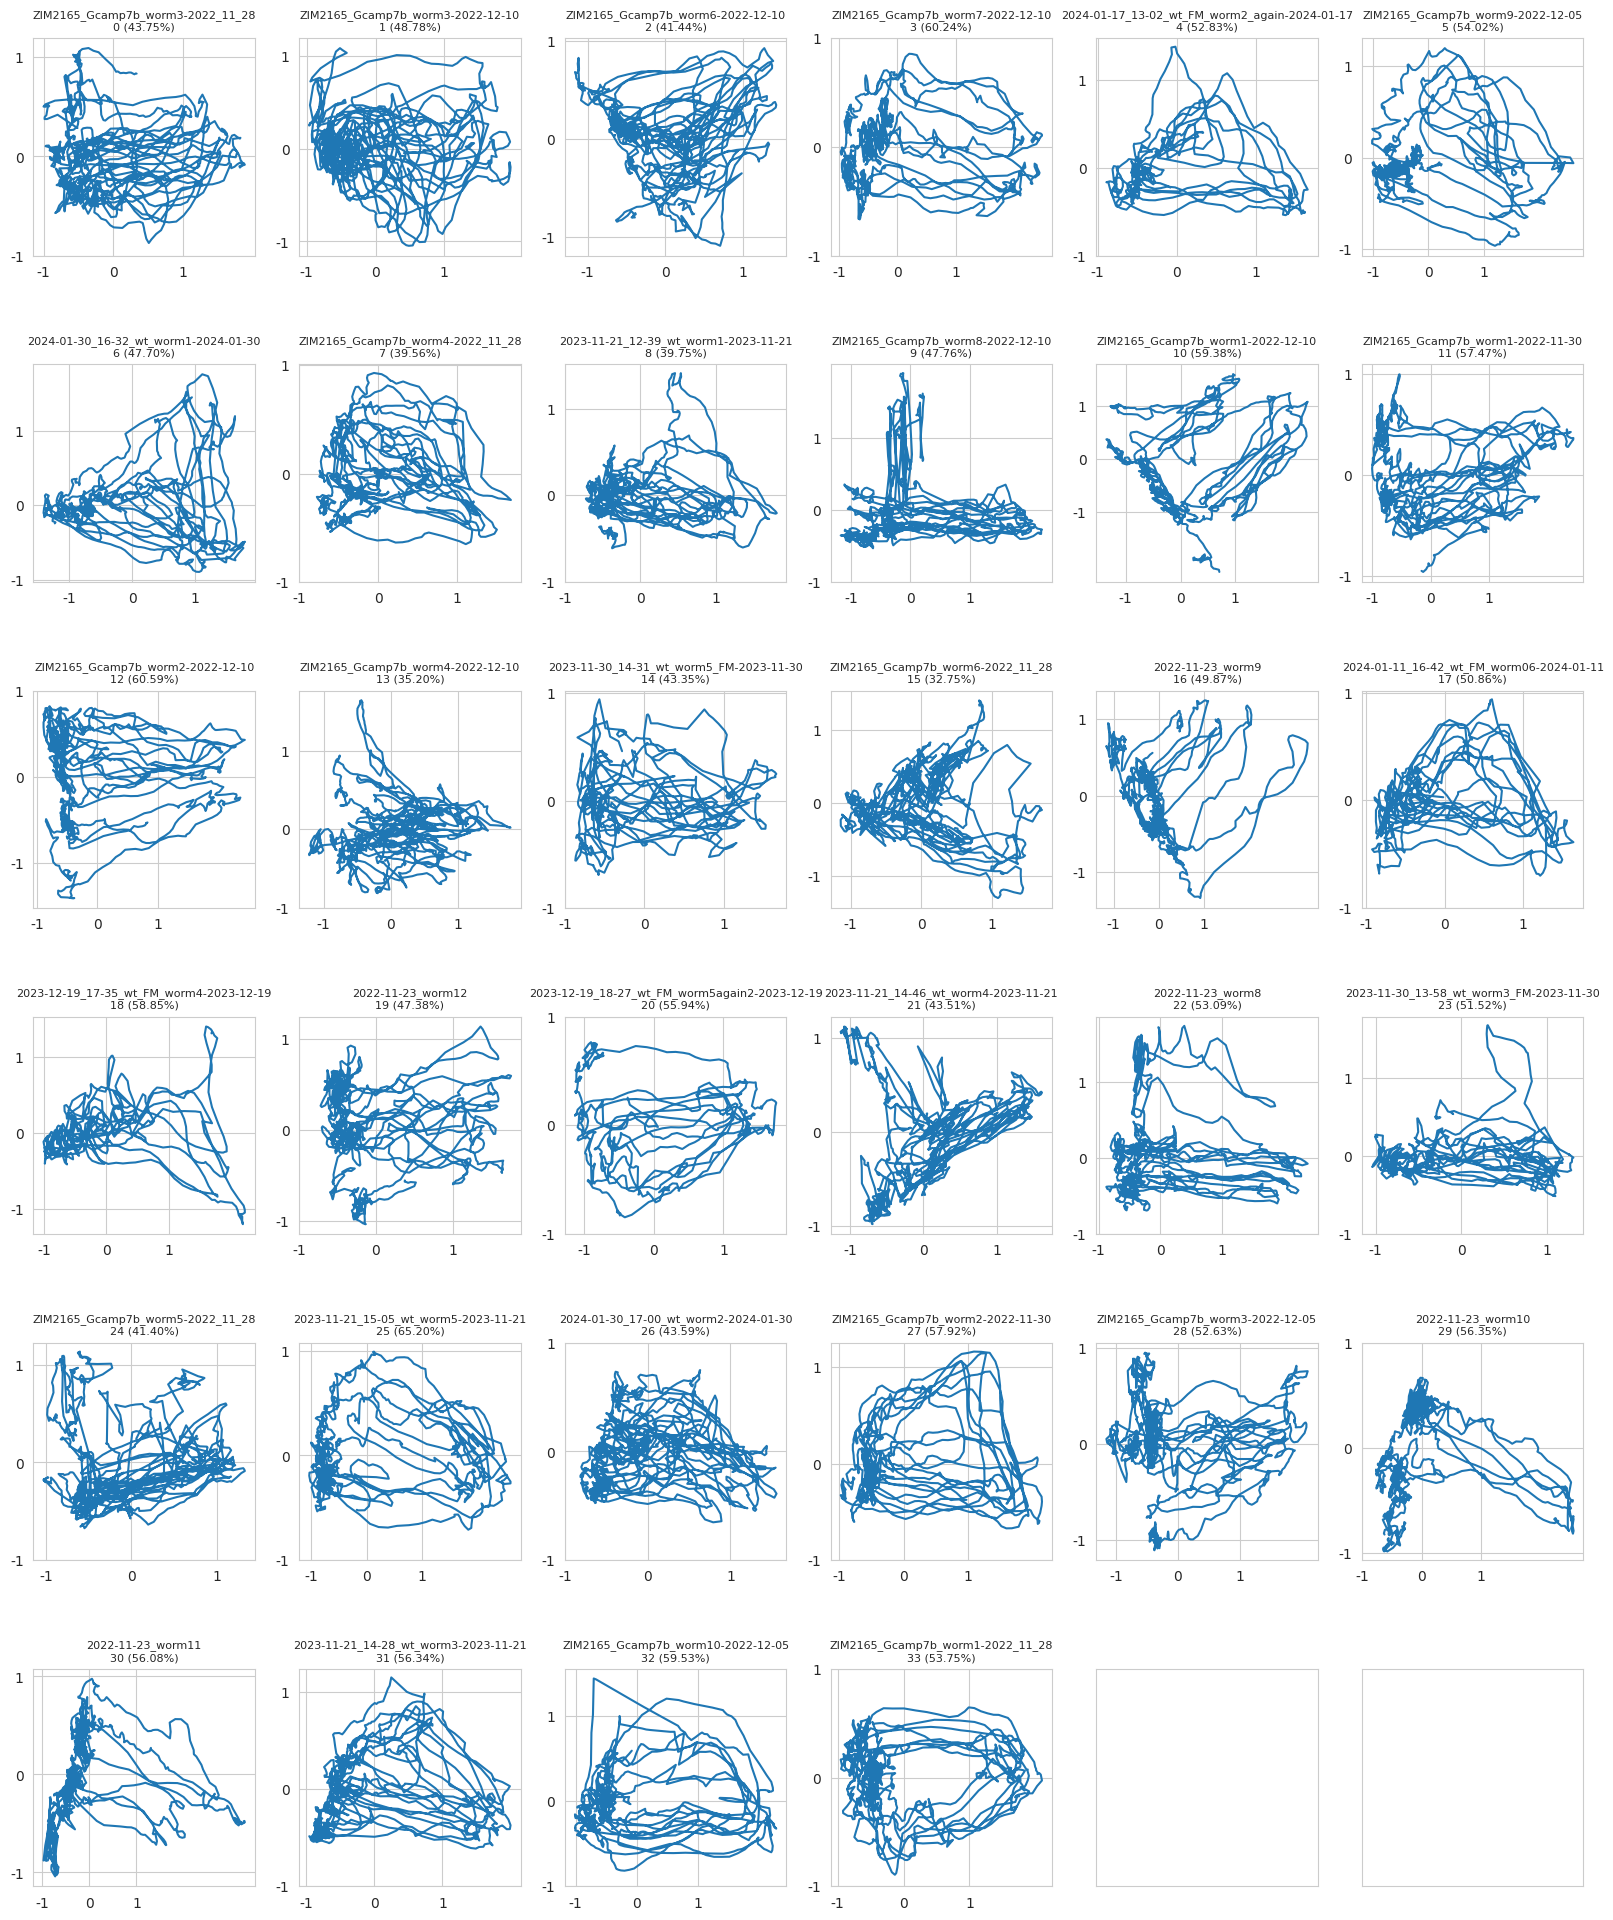

In [12]:
modes_manifold = list()
traces_manifold = list()
vars_expl = list()
for trace, ds in zip(traces, discrete_states):

	pca = PCA(n_components=2)
	trace_reduced = pca.fit_transform(trace)
	trace_reconstructed = pca.inverse_transform(trace_reduced)
	modes_manifold.append(trace_reduced)
	traces_manifold.append(trace_reconstructed)

	vars_expl.append(pca.explained_variance_ratio_)


n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 24))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

scale = [-1, 0, 1]
for i, signal in enumerate(modes_manifold):
	axes[i // dim, i % dim].plot(signal[:, 0], signal[:, 1])
	axes[i // dim, i % dim].set_xticks(scale)
	axes[i // dim, i % dim].set_xticklabels(scale)
	axes[i // dim, i % dim].set_yticks(scale)
	axes[i // dim, i % dim].set_yticklabels(scale)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n{i} ({sum(vars_expl[i]) * 100:.2f}%)', fontsize=8)

plt.subplots_adjust(hspace=0.5)
print(np.array([sum(var_expl) for var_expl in vars_expl]).mean())

# STUFF

In [13]:
ids_chosen = [3, 10, 11, 12, 18, 25, 27, 32]
modes_manifold_chosen = [modes_manifold[i] for i in ids_chosen]

Text(0.5, 1.0, 'mean pca')

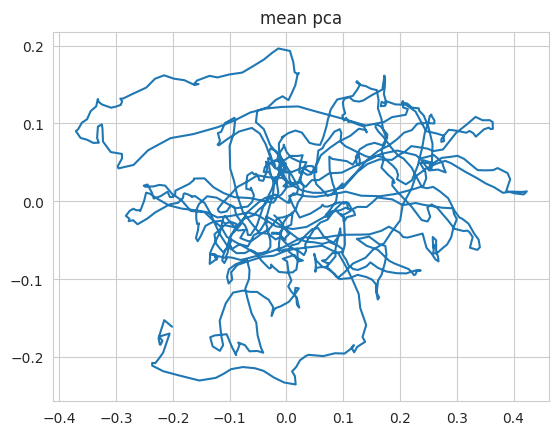

In [14]:
modes_manifold_chosen_pp = list()
for modes in modes_manifold:
	if len(modes) > 1167:
		modes_manifold_chosen_pp.append(modes[:1167])
	if len(modes) == 1166:
		modes_manifold_chosen_pp.append(modes + np.empty(modes[0].shape))
	if len(modes) < 1166:
		continue

mean = np.mean(np.array(modes_manifold_chosen_pp), axis=0)
plt.plot(mean[:, 0], mean[:, 1])
plt.title('mean pca')

In [15]:
traces_chosen = [traces[i] for i in ids_chosen]

In [16]:
min_neurons = min([array.shape[1] for array in traces_chosen])
traces_chosen_concat = np.empty((0, min_neurons))
for trace in traces_chosen:
	traces_chosen_concat = np.concatenate([traces_chosen_concat, trace.values[:, :min_neurons]])

Text(0.5, 1.0, 'concat pca')

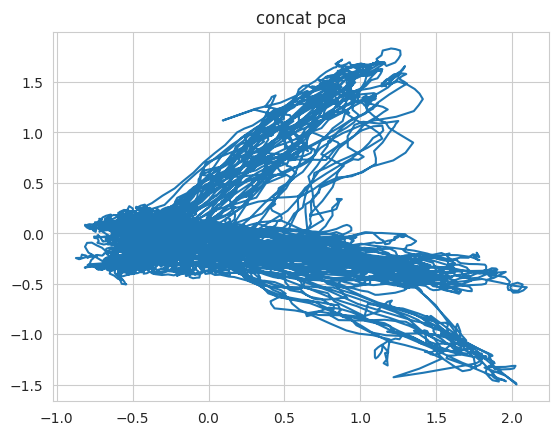

In [17]:
pca_all = PCA(n_components=2)
modes_manifold_chosen_concat = pca_all.fit_transform(traces_chosen_concat)
plt.plot(modes_manifold_chosen_concat[:, 0], modes_manifold_chosen_concat[:, 1])
plt.title('concat pca')

Text(0.5, 1.0, 'scaled concat pca')

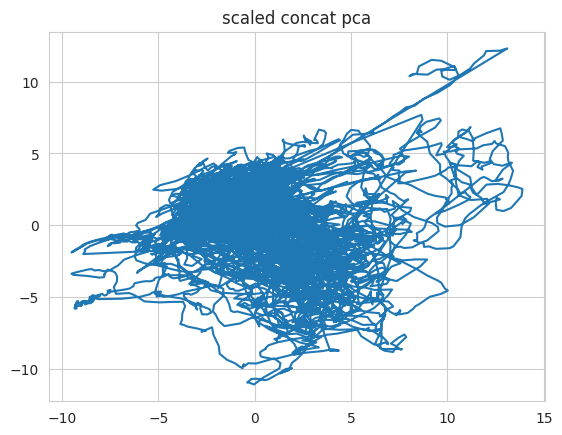

In [18]:
scaler = StandardScaler()
traces_chosen_concat_scaled = scaler.fit_transform(traces_chosen_concat)
pca_all = PCA(n_components=2)
modes_manifold_chosen_concat_scaled = pca_all.fit_transform(traces_chosen_concat_scaled)
plt.plot(modes_manifold_chosen_concat_scaled[:, 0], modes_manifold_chosen_concat_scaled[:, 1])
plt.title('scaled concat pca')